# Analisis Data E-Commerce Olist

**Proyek akhir analisis data Dicoding | Bahasa: Python**

Notebook ini menganalisis performa pesanan, kategori produk, kepuasan pelanggan, dan ketepatan pengiriman pada Brazilian E-Commerce Public Dataset by Olist. Semua angka penjualan dihitung dari `price` pada tabel item, sehingga **tidak mencakup ongkos kirim**. Mata uang sumber data adalah real Brasil (BRL/R$).

**Sumber dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (lisensi CC BY-NC-SA 4.0).

**Periode analisis utama:** 1 Januari 2017 sampai 31 Agustus 2018. Data akhir 2016 dan September–Oktober 2018 tidak dipakai untuk tren bulanan karena cakupannya sangat jarang/tidak lengkap. Ini menghindari kesimpulan tren yang sekadar mencerminkan batas pengumpulan data.

## 1. Menentukan Pertanyaan Bisnis dengan SMART

1. **Tren pesanan dan penjualan:** Bagaimana jumlah pesanan berstatus *delivered* dan total nilai barang (tanpa ongkir) berubah setiap bulan selama Januari 2017–Agustus 2018, dan bulan mana yang mencatat nilai tertinggi? Hasilnya membantu perencanaan promosi dan kapasitas operasional.
2. **Kategori produk:** Kategori produk apa yang menghasilkan nilai penjualan barang tertinggi, dan kategori mana yang memiliki rata-rata skor ulasan terendah di antara kategori dengan minimal 100 ulasan pada Januari 2017–Agustus 2018? Hasilnya membantu menentukan prioritas stok dan evaluasi kualitas layanan/produk.
3. **Ketepatan pengiriman:** Seberapa besar perbedaan rata-rata skor ulasan dan proporsi ulasan rendah (skor 1–2) antara pesanan yang terlambat dan pesanan yang tiba tepat waktu/lebih cepat selama Januari 2017–Agustus 2018? Hasilnya membantu menentukan prioritas perbaikan logistik.

Pertanyaan tersebut spesifik pada metrik, dapat dihitung, relevan untuk keputusan e-commerce, berorientasi tindakan, dan memiliki batas waktu yang jelas.

## 2. Gathering Data

Dataset terdiri atas beberapa tabel relasional. Tabel yang digunakan adalah pesanan, item pesanan, pelanggan, produk, ulasan, serta terjemahan kategori. Tabel geolokasi dan pembayaran tidak dipakai karena tidak dibutuhkan untuk menjawab tiga pertanyaan bisnis di atas.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='deep')

DATA_DIR = Path('data')
orders_raw = pd.read_csv(DATA_DIR / 'orders_dataset.csv')
items_raw = pd.read_csv(DATA_DIR / 'order_items_dataset.csv')
customers_raw = pd.read_csv(DATA_DIR / 'customers_dataset.csv')
products_raw = pd.read_csv(DATA_DIR / 'products_dataset.csv')
reviews_raw = pd.read_csv(DATA_DIR / 'order_reviews_dataset.csv')
translations = pd.read_csv(DATA_DIR / 'product_category_name_translation.csv')

frames = {
    'orders': orders_raw,
    'order_items': items_raw,
    'customers': customers_raw,
    'products': products_raw,
    'reviews': reviews_raw,
    'category_translation': translations,
}
data_inventory = pd.DataFrame([
    {'Tabel': name, 'Jumlah baris': len(df), 'Jumlah kolom': df.shape[1]}
    for name, df in frames.items()
])
display(data_inventory)

,Tabel,Jumlah baris,Jumlah kolom
0,orders,99441,8
1,order_items,112650,7
2,customers,99441,5
3,products,32951,9
4,reviews,99224,7
5,category_translation,71,2


**Rangkuman gathering data:** keenam tabel berhasil dimuat ke DataFrame. Data pesanan menjadi tabel utama, sedangkan tabel lain digabung menggunakan kunci `order_id`, `customer_id`, dan `product_id` sesuai relasinya. Tingkat data perlu diperhatikan: satu pesanan dapat berisi beberapa item, jadi jumlah baris item tidak boleh dianggap sama dengan jumlah pesanan.

## 3. Assessing Data

Pemeriksaan mencakup ukuran tabel, *missing value*, duplikasi kunci, rentang nilai, dan kelengkapan tanggal. Missing timestamp pada pesanan yang belum terkirim tidak otomatis dianggap kesalahan karena status pesanan memang bisa belum selesai.

In [2]:
# Konversi waktu untuk pemeriksaan kualitas; nilai yang tidak tersedia dipertahankan sebagai NaT.
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
orders_check = orders_raw.copy()
for col in date_cols:
    orders_check[col] = pd.to_datetime(orders_check[col], errors='coerce')

missing_rows = []
for name, df in frames.items():
    for col in df.columns:
        n_missing = int(df[col].isna().sum())
        if n_missing:
            missing_rows.append({'Tabel': name, 'Kolom': col, 'Missing': n_missing, 'Persentase (%)': n_missing / len(df) * 100})
missing_summary = pd.DataFrame(missing_rows).sort_values(['Tabel','Missing'], ascending=[True,False])
display(missing_summary)

quality_checks = pd.DataFrame([
    {'Pemeriksaan': 'order_id duplikat di tabel orders', 'Jumlah': int(orders_raw['order_id'].duplicated().sum())},
    {'Pemeriksaan': 'Kunci (order_id, order_item_id) duplikat', 'Jumlah': int(items_raw.duplicated(['order_id','order_item_id']).sum())},
    {'Pemeriksaan': 'Baris dengan review_id berulang setelah kemunculan pertama', 'Jumlah': int(reviews_raw['review_id'].duplicated().sum())},
    {'Pemeriksaan': 'Nilai review_id yang terhubung ke lebih dari satu baris', 'Jumlah': int(reviews_raw.loc[reviews_raw['review_id'].duplicated(keep=False), 'review_id'].nunique())},
    {'Pemeriksaan': 'Produk tanpa kategori', 'Jumlah': int(products_raw['product_category_name'].isna().sum())},
    {'Pemeriksaan': 'Harga item <= 0', 'Jumlah': int((items_raw['price'] <= 0).sum())},
    {'Pemeriksaan': 'Skor ulasan di luar rentang 1–5', 'Jumlah': int((~reviews_raw['review_score'].between(1,5)).sum())},
    {'Pemeriksaan': 'Pesanan delivered tanpa tanggal diterima pelanggan', 'Jumlah': int((orders_raw['order_status'].eq('delivered') & orders_check['order_delivered_customer_date'].isna()).sum())},
])
display(quality_checks)

,Tabel,Kolom,Missing,Persentase (%)
2,orders,order_delivered_customer_date,2965,2.98
1,orders,order_delivered_carrier_date,1783,1.79
0,orders,order_approved_at,160,0.16
3,products,product_category_name,610,1.85
4,products,product_name_lenght,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,products,product_weight_g,2,0.01
8,products,product_length_cm,2,0.01
9,products,product_height_cm,2,0.01


,Pemeriksaan,Jumlah
0,order_id duplikat di tabel orders,0
1,"Kunci (order_id, order_item_id) duplikat",0
2,Baris dengan review_id berulang setelah kemunc...,814
3,Nilai review_id yang terhubung ke lebih dari s...,789
4,Produk tanpa kategori,610
5,Harga item <= 0,0
6,Skor ulasan di luar rentang 1–5,0
7,Pesanan delivered tanpa tanggal diterima pelan...,8


### Temuan kualitas dan rencana penanganan

- **Kategori produk kosong:** isi dengan label `Unknown category` setelah proses penggabungan agar baris item tetap terhitung tanpa mengarang kategori.
- **ID ulasan tidak unik:** sejumlah `review_id` muncul pada beberapa pesanan. Karena hubungan ulasan-ke-pesanan menjadi ambigu, baris dengan ID ulasan yang berulang dikeluarkan dari analisis ulasan. Ini lebih transparan daripada menganggap salinan tersebut sebagai ulasan independen.
- **Tanggal pengiriman kosong:** pertahankan sebagai nilai kosong. Pesanan tetap dapat digunakan untuk analisis penjualan jika statusnya delivered, tetapi tidak dipakai untuk perbandingan keterlambatan jika tanggal aktual tidak tersedia.
- **Periode data tidak merata:** tren bulanan dibatasi ke Januari 2017–Agustus 2018. Bulan lain tidak dipakai dalam perbandingan bulanan.
- **Tidak ditemukan harga item nonpositif atau skor ulasan di luar 1–5** pada pemeriksaan awal, sehingga tidak dilakukan perubahan buatan pada nilai tersebut.

## 4. Cleaning Data

Tahap ini mengubah tanggal menjadi tipe datetime, menangani kategori kosong, menghapus ulasan dengan identifier ambigu dari metrik ulasan, lalu membentuk tabel analisis pada tingkat pesanan dan tingkat item. Data tidak dibuang secara massal hanya karena kolom yang tidak relevan memiliki missing value.

In [3]:
orders = orders_raw.copy()
items = items_raw.copy()
customers = customers_raw.copy()
products = products_raw.copy()
reviews = reviews_raw.copy()

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')
reviews['review_score'] = pd.to_numeric(reviews['review_score'], errors='coerce')

# Hanya ulasan yang review_id-nya tidak ambigu yang digunakan untuk metrik rating.
ambiguous_review_ids = reviews.loc[reviews['review_id'].duplicated(keep=False), 'review_id'].unique()
reviews_clean = reviews[~reviews['review_id'].isin(ambiguous_review_ids)].copy()
reviews_by_order = reviews_clean.groupby('order_id').agg(
    review_score=('review_score','mean'),
    review_count=('review_id','nunique')
).reset_index()

product_category = products[['product_id','product_category_name']].merge(
    translations, on='product_category_name', how='left'
)
product_category['category'] = (
    product_category['product_category_name_english']
    .fillna(product_category['product_category_name'])
    .fillna('Unknown category')
)

START_DATE = pd.Timestamp('2017-01-01')
END_DATE_EXCLUSIVE = pd.Timestamp('2018-09-01')
analysis_orders = orders[
    orders['order_status'].eq('delivered')
    & orders['order_purchase_timestamp'].ge(START_DATE)
    & orders['order_purchase_timestamp'].lt(END_DATE_EXCLUSIVE)
].copy()

order_items = items.merge(
    analysis_orders[['order_id','order_purchase_timestamp']], on='order_id', how='inner'
).merge(product_category[['product_id','category']], on='product_id', how='left')
order_items['category'] = order_items['category'].fillna('Unknown category')
order_items = order_items.rename(columns={'order_purchase_timestamp':'purchase_date'})

item_summary = items.groupby('order_id').agg(
    item_revenue=('price','sum'),
    item_count=('order_item_id','count'),
    freight_total=('freight_value','sum')
).reset_index()
orders_clean = analysis_orders.merge(
    customers[['customer_id','customer_unique_id','customer_state']], on='customer_id', how='left'
).merge(item_summary, on='order_id', how='left').merge(reviews_by_order, on='order_id', how='left')
orders_clean['delay_days'] = (
    orders_clean['order_delivered_customer_date'].dt.normalize()
    - orders_clean['order_estimated_delivery_date'].dt.normalize()
).dt.days
orders_clean['delivery_group'] = np.select(
    [orders_clean['delay_days'].gt(0), orders_clean['delay_days'].notna()],
    ['Terlambat','Tepat waktu / lebih cepat'],
    default='Tidak diketahui'
)

print(f'Pesanan delivered pada periode analisis: {orders_clean.order_id.nunique():,}')
print(f'Baris item pada periode analisis: {len(order_items):,}')
print(f'ID ulasan ambigu yang dikeluarkan: {len(ambiguous_review_ids):,}')
print(f'Baris ulasan yang dikeluarkan karena ID ambigu: {len(reviews) - len(reviews_clean):,}')
print(f'Kategori Unknown category: {(order_items.category == "Unknown category").sum():,} baris item')
display(orders_clean[['order_id','order_purchase_timestamp','item_revenue','item_count','delay_days','delivery_group','review_score']].head())

Pesanan delivered pada periode analisis: 96,211
Baris item pada periode analisis: 109,880
ID ulasan ambigu yang dikeluarkan: 789
Baris ulasan yang dikeluarkan karena ID ambigu: 1,603
Kategori Unknown category: 1,535 baris item


,order_id,order_purchase_timestamp,item_revenue,item_count,delay_days,delivery_group,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,29.99,1,-8.00,Tepat waktu / lebih cepat,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,118.70,1,-6.00,Tepat waktu / lebih cepat,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,159.90,1,-18.00,Tepat waktu / lebih cepat,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,45.00,1,-13.00,Tepat waktu / lebih cepat,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,19.90,1,-10.00,Tepat waktu / lebih cepat,5.00


**Rangkuman cleaning:** data analisis sekarang memisahkan grain pesanan dari grain item. Nilai penjualan dihitung dengan menjumlahkan `price` per item, sedangkan metrik keterlambatan hanya diinterpretasikan pada pesanan dengan tanggal pengiriman aktual tersedia. Rating dihitung dari ulasan yang identifier-nya tidak ambigu.

## 5. Exploratory Data Analysis (EDA)

### EDA 1: Tren pesanan dan penjualan bulanan

Metrik penjualan adalah total `price` item dari pesanan berstatus delivered. Ongkos kirim tidak termasuk. Bulan di bawah sudah dibatasi pada Januari 2017–Agustus 2018.

In [4]:
monthly_orders = orders_clean.assign(month=orders_clean['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()).groupby('month').agg(
    delivered_orders=('order_id','nunique')
)
monthly_revenue = order_items.assign(month=order_items['purchase_date'].dt.to_period('M').dt.to_timestamp()).groupby('month').agg(
    item_revenue=('price','sum')
)
month_index = pd.date_range('2017-01-01','2018-08-01',freq='MS')
monthly = monthly_orders.join(monthly_revenue, how='outer').reindex(month_index).fillna(0)
monthly.index.name = 'month'
monthly = monthly.reset_index()
monthly['month_label'] = monthly['month'].dt.strftime('%Y-%m')

peak_orders = monthly.loc[monthly['delivered_orders'].idxmax()]
peak_revenue = monthly.loc[monthly['item_revenue'].idxmax()]
print(f"Puncak jumlah pesanan: {peak_orders['month_label']} ({peak_orders['delivered_orders']:,.0f} pesanan)")
print(f"Puncak nilai barang: {peak_revenue['month_label']} (R$ {peak_revenue['item_revenue']:,.2f})")
display(monthly.sort_values('item_revenue',ascending=False).head(5)[['month_label','delivered_orders','item_revenue']])

Puncak jumlah pesanan: 2017-11 (7,289 pesanan)
Puncak nilai barang: 2017-11 (R$ 987,765.37)


,month_label,delivered_orders,item_revenue
10,2017-11,7289,"987,765.37"
16,2018-05,6749,"977,544.69"
15,2018-04,6798,"973,534.09"
14,2018-03,7003,"953,356.25"
12,2018-01,7069,"924,645.00"


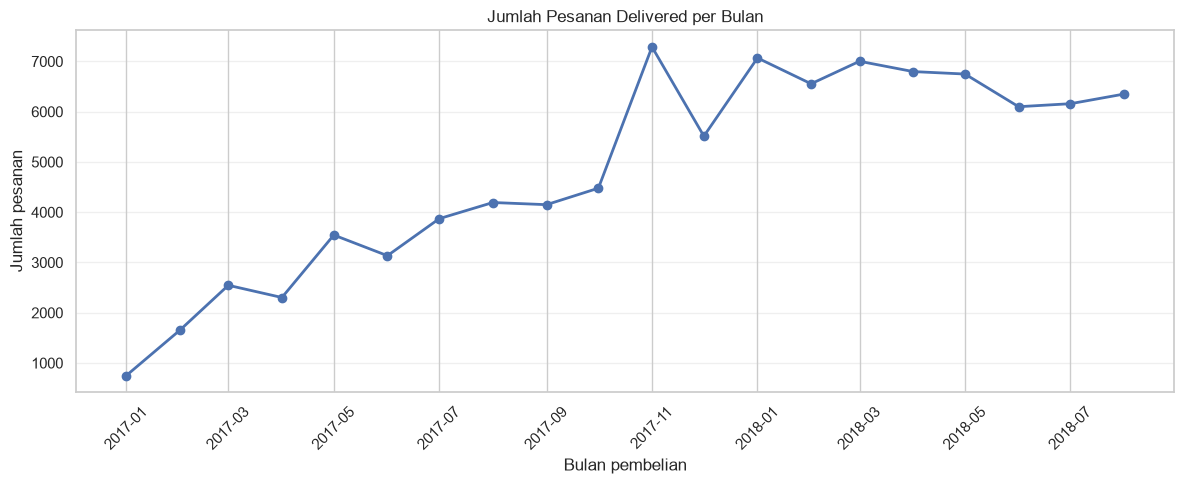

In [5]:
fig, ax = plt.subplots(figsize=(12,5))
ax.plot(monthly['month'], monthly['delivered_orders'], marker='o', linewidth=2)
ax.set_title('Jumlah Pesanan Delivered per Bulan')
ax.set_xlabel('Bulan pembelian')
ax.set_ylabel('Jumlah pesanan')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

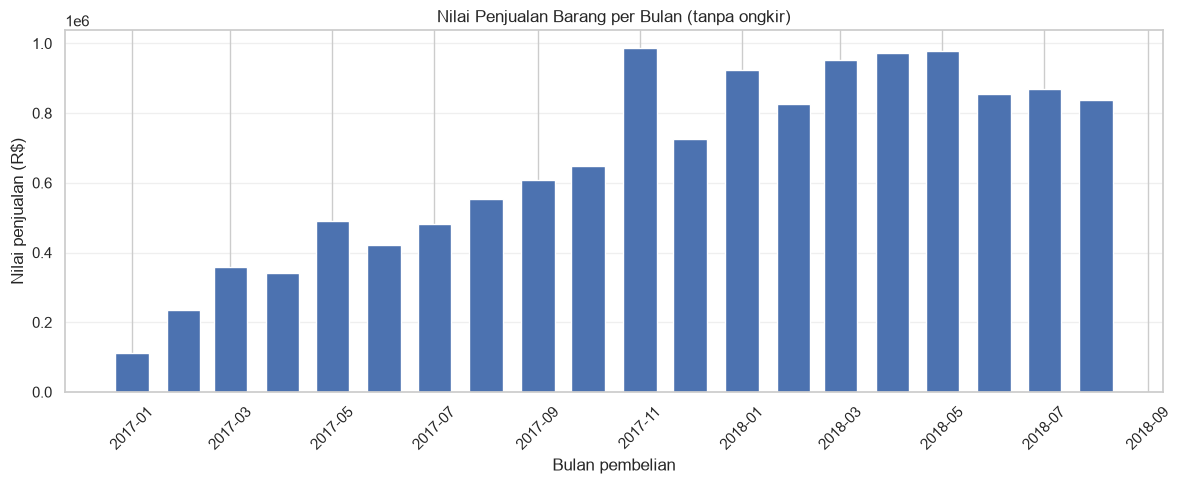

In [6]:
fig, ax = plt.subplots(figsize=(12,5))
ax.bar(monthly['month'], monthly['item_revenue'], width=20)
ax.set_title('Nilai Penjualan Barang per Bulan (tanpa ongkir)')
ax.set_xlabel('Bulan pembelian')
ax.set_ylabel('Nilai penjualan (R$)')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

### EDA 2: Kategori produk, nilai penjualan, dan ulasan

Pendapatan kategori dihitung pada tingkat item. Untuk rating kategori, setiap kombinasi pesanan-kategori dihitung satu kali agar pesanan yang berisi banyak item dalam kategori yang sama tidak memberi bobot berlebih.

In [7]:
category_sales = order_items.groupby('category').agg(
    item_revenue=('price','sum'),
    items_sold=('order_item_id','count'),
    orders=('order_id','nunique')
).reset_index()
order_category = order_items[['order_id','category']].drop_duplicates()
category_reviews = order_category.merge(reviews_by_order[['order_id','review_score']], on='order_id', how='left').groupby('category').agg(
    avg_review_score=('review_score','mean'),
    reviewed_orders=('review_score','count')
).reset_index()
category_analysis = category_sales.merge(category_reviews, on='category', how='left')
category_top = category_analysis.sort_values('item_revenue', ascending=False).head(10)
category_low_rating = category_analysis[category_analysis['reviewed_orders'] >= 100].sort_values('avg_review_score').head(8)
print('10 kategori dengan nilai penjualan barang terbesar:')
display(category_top[['category','item_revenue','items_sold','orders','avg_review_score','reviewed_orders']])
print('Kategori dengan rating terendah (minimal 100 ulasan):')
display(category_low_rating[['category','item_revenue','avg_review_score','reviewed_orders']])

10 kategori dengan nilai penjualan barang terbesar:


,category,item_revenue,items_sold,orders,avg_review_score,reviewed_orders
44,health_beauty,"1,229,557.50",9422,8610,4.23,8468
73,watches_gifts,"1,163,465.91",5855,5491,4.12,5429
8,bed_bath_table,"1,022,955.77",10945,9267,4.01,8976
68,sports_leisure,"952,840.40",8414,7513,4.23,7361
16,computers_accessories,"888,055.59",7632,6518,4.09,6387
40,furniture_decor,"706,237.17",8095,6258,4.07,6084
50,housewares,"614,341.62",6783,5734,4.20,5663
21,cool_stuff,"609,158.00",3711,3552,4.22,3513
6,auto,"577,838.39",4132,3802,4.15,3760
43,garden_tools,"469,135.40",4263,3443,4.18,3407


Kategori dengan rating terendah (minimal 100 ulasan):


,category,item_revenue,avg_review_score,reviewed_orders
58,office_furniture,"266,853.43",3.66,1225
5,audio,"50,413.61",3.83,343
31,fashion_male_clothing,"10,427.43",3.84,103
48,home_confort,"58,008.45",3.90,386
35,fixed_telephony,"54,610.33",3.97,204
20,construction_tools_safety,"38,773.22",3.97,158
49,home_construction,"81,407.57",3.98,477
34,fashion_underwear_beach,"9,305.95",3.99,114


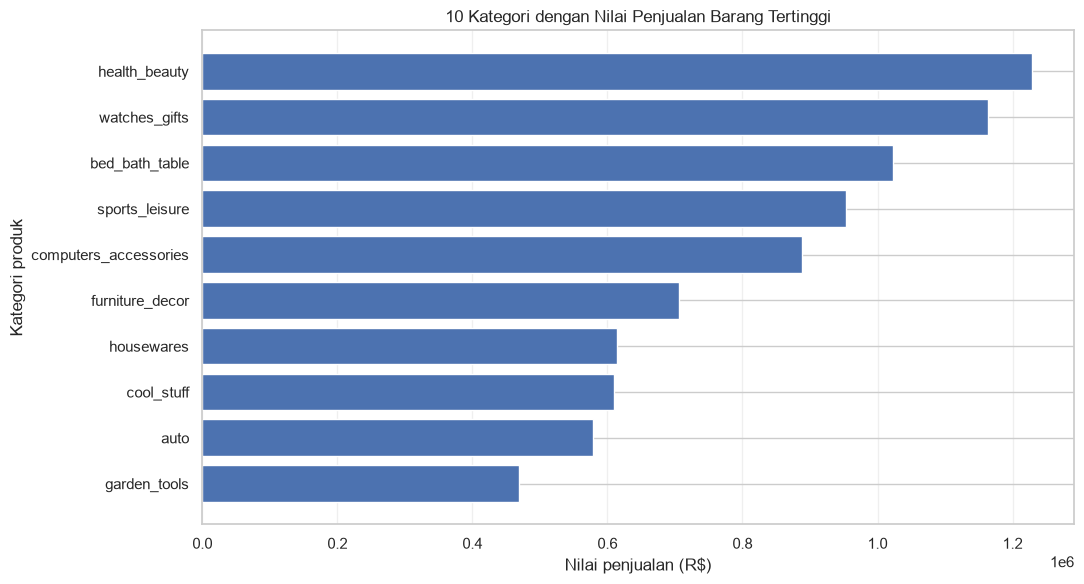

In [8]:
fig, ax = plt.subplots(figsize=(11,6))
plot_data = category_top.sort_values('item_revenue', ascending=True)
ax.barh(plot_data['category'], plot_data['item_revenue'])
ax.set_title('10 Kategori dengan Nilai Penjualan Barang Tertinggi')
ax.set_xlabel('Nilai penjualan (R$)')
ax.set_ylabel('Kategori produk')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
plt.show()

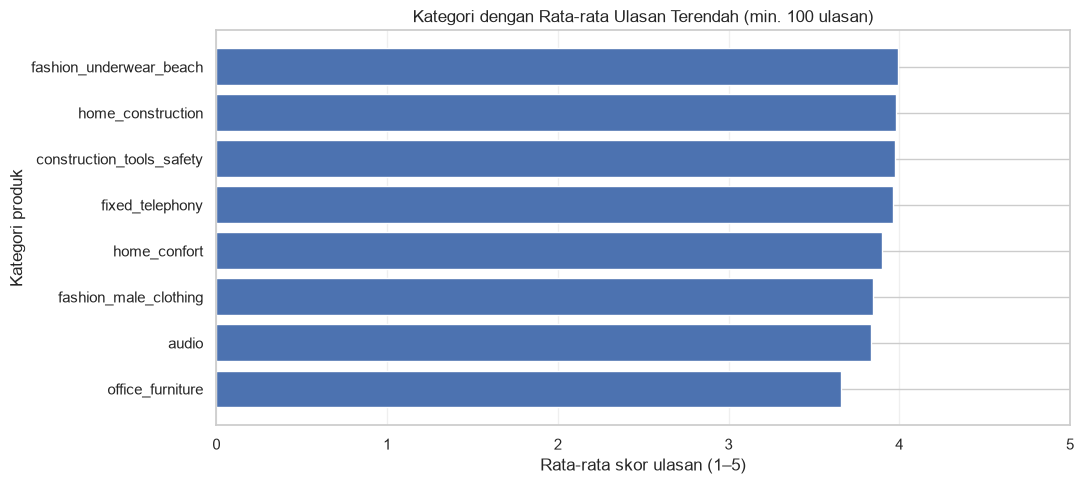

In [9]:
fig, ax = plt.subplots(figsize=(11,5))
plot_data = category_low_rating.sort_values('avg_review_score', ascending=True)
ax.barh(plot_data['category'], plot_data['avg_review_score'])
ax.set_title('Kategori dengan Rata-rata Ulasan Terendah (min. 100 ulasan)')
ax.set_xlabel('Rata-rata skor ulasan (1–5)')
ax.set_ylabel('Kategori produk')
ax.set_xlim(0,5)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
plt.show()

### EDA 3: Ketepatan pengiriman dan kepuasan

Definisi keterlambatan: tanggal barang diterima pelanggan lebih akhir daripada tanggal estimasi. `delay_days > 0` berarti terlambat; nilai nol atau negatif berarti tepat waktu/lebih cepat. Untuk membandingkan rating, pesanan harus memiliki skor ulasan yang valid dan tidak ambigu.

In [10]:
delivery_rated = orders_clean[orders_clean['review_score'].notna() & orders_clean['delay_days'].notna()].copy()
delivery_summary = delivery_rated.groupby('delivery_group').agg(
    reviewed_orders=('order_id','nunique'),
    avg_review_score=('review_score','mean'),
    low_review_share=('review_score', lambda s: (s <= 2).mean() * 100),
    avg_delay_days=('delay_days','mean')
).reset_index()
delivery_summary = delivery_summary.sort_values('delivery_group')
display(delivery_summary)

score_map = delivery_summary.set_index('delivery_group')['avg_review_score']
low_map = delivery_summary.set_index('delivery_group')['low_review_share']
if {'Terlambat','Tepat waktu / lebih cepat'}.issubset(score_map.index):
    score_gap = score_map['Tepat waktu / lebih cepat'] - score_map['Terlambat']
    low_gap = low_map['Terlambat'] - low_map['Tepat waktu / lebih cepat']
    print(f'Selisih rata-rata rating (tepat waktu/lebih cepat dikurangi terlambat): {score_gap:.2f} poin.')
    print(f'Selisih proporsi rating rendah (terlambat dikurangi tepat waktu/lebih cepat): {low_gap:.2f} poin persentase.')

,delivery_group,reviewed_orders,avg_review_score,low_review_share,avg_delay_days
0,Tepat waktu / lebih cepat,88210,4.30,9.14,-13.43
1,Terlambat,6304,2.27,62.34,10.49


Selisih rata-rata rating (tepat waktu/lebih cepat dikurangi terlambat): 2.02 poin.
Selisih proporsi rating rendah (terlambat dikurangi tepat waktu/lebih cepat): 53.21 poin persentase.


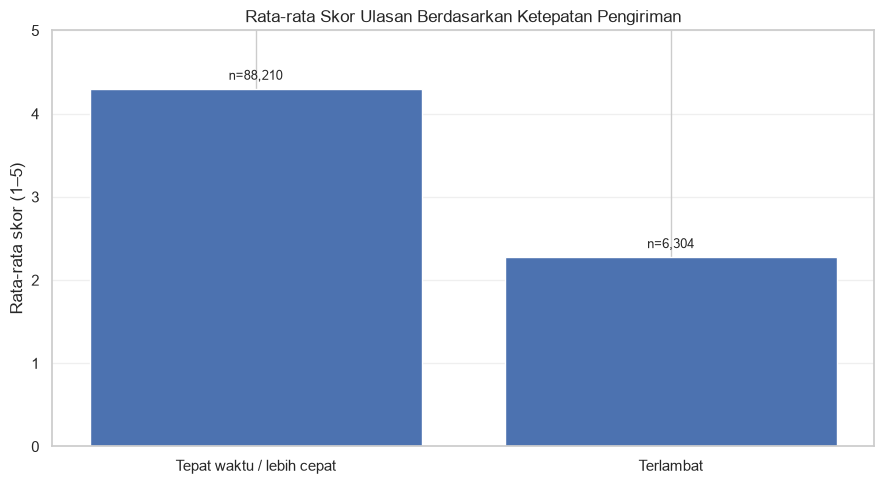

In [11]:
fig, ax = plt.subplots(figsize=(9,5))
plot_data = delivery_summary.set_index('delivery_group').reindex(['Tepat waktu / lebih cepat','Terlambat']).dropna(subset=['avg_review_score'])
bars = ax.bar(plot_data.index, plot_data['avg_review_score'])
ax.set_title('Rata-rata Skor Ulasan Berdasarkan Ketepatan Pengiriman')
ax.set_ylabel('Rata-rata skor (1–5)')
ax.set_ylim(0,5)
ax.grid(axis='y', alpha=0.3)
for bar, n in zip(bars, plot_data['reviewed_orders']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.08, f'n={n:,.0f}', ha='center', va='bottom', fontsize=9)
fig.tight_layout()
plt.show()

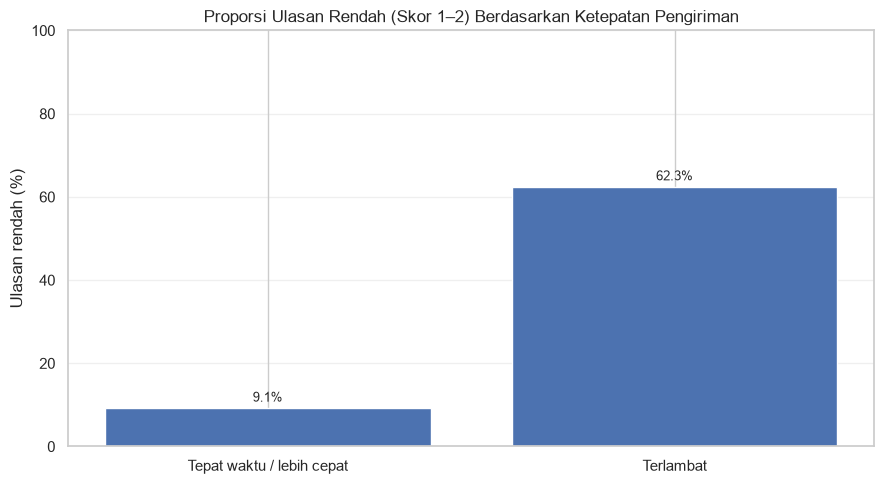

In [12]:
fig, ax = plt.subplots(figsize=(9,5))
plot_data = delivery_summary.set_index('delivery_group').reindex(['Tepat waktu / lebih cepat','Terlambat']).dropna(subset=['low_review_share'])
bars = ax.bar(plot_data.index, plot_data['low_review_share'])
ax.set_title('Proporsi Ulasan Rendah (Skor 1–2) Berdasarkan Ketepatan Pengiriman')
ax.set_ylabel('Ulasan rendah (%)')
ax.set_ylim(0,100)
ax.grid(axis='y', alpha=0.3)
for bar, value in zip(bars, plot_data['low_review_share']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{value:.1f}%', ha='center', va='bottom', fontsize=9)
fig.tight_layout()
plt.show()

## 6. Analisis Lanjutan: RFM dan Segmentasi Pelanggan

RFM digunakan untuk membandingkan pelanggan berdasarkan **Recency** (berapa hari sejak pembelian terakhir), **Frequency** (jumlah pesanan), dan **Monetary** (total nilai barang). Ini adalah segmentasi berbasis aturan bisnis, bukan model machine learning. Snapshot ditetapkan pada 1 September 2018, tepat setelah akhir periode analisis.

In [13]:
rfm_base = orders_clean[['order_id','customer_id','order_purchase_timestamp','item_revenue']].merge(
    customers[['customer_id','customer_unique_id']], on='customer_id', how='left'
)
SNAPSHOT_DATE = pd.Timestamp('2018-09-01')
rfm = rfm_base.groupby('customer_unique_id').agg(
    last_purchase=('order_purchase_timestamp','max'),
    frequency=('order_id','nunique'),
    monetary=('item_revenue','sum')
).reset_index()
rfm['recency_days'] = (SNAPSHOT_DATE - rfm['last_purchase'].dt.normalize()).dt.days
rfm['R_score'] = pd.cut(rfm['recency_days'], bins=[-1,30,90,180,np.inf], labels=[4,3,2,1]).astype(int)
rfm['F_score'] = np.select([rfm['frequency'] >= 4, rfm['frequency'] == 3, rfm['frequency'] == 2], [4,3,2], default=1).astype(int)
rfm['M_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['RFM_score'] = rfm['R_score'] + rfm['F_score'] + rfm['M_score']
rfm['segment'] = np.select(
    [
        (rfm['frequency'] >= 3) & (rfm['R_score'] >= 3) & (rfm['M_score'] >= 3),
        (rfm['frequency'] >= 2) & (rfm['R_score'] >= 3),
        (rfm['frequency'] >= 2) & (rfm['R_score'] <= 2),
        rfm['frequency'] == 1,
    ],
    ['Bernilai tinggi', 'Pelanggan potensial', 'Perlu diaktifkan kembali', 'Pembeli satu kali'],
    default='Pelanggan berulang lainnya'
)
rfm_summary = rfm.groupby('segment').agg(
    customers=('customer_unique_id','nunique'),
    total_item_revenue=('monetary','sum'),
    avg_item_spend=('monetary','mean'),
    median_recency_days=('recency_days','median')
).reset_index().sort_values('customers', ascending=False)
display(rfm_summary)
repeat_share = (rfm['frequency'] >= 2).mean() * 100
print(f"Pelanggan yang melakukan minimal 2 pesanan dalam periode analisis: {repeat_share:.2f}%")

,segment,customers,total_item_revenue,avg_item_spend,median_recency_days
2,Pembeli satu kali,90315,"12,455,672.09",137.91,222.00
3,Perlu diaktifkan kembali,2186,"563,384.91",257.72,250.50
1,Pelanggan potensial,550,"132,300.83",240.55,45.00
0,Bernilai tinggi,53,"29,669.30",559.80,40.00


Pelanggan yang melakukan minimal 2 pesanan dalam periode analisis: 3.00%


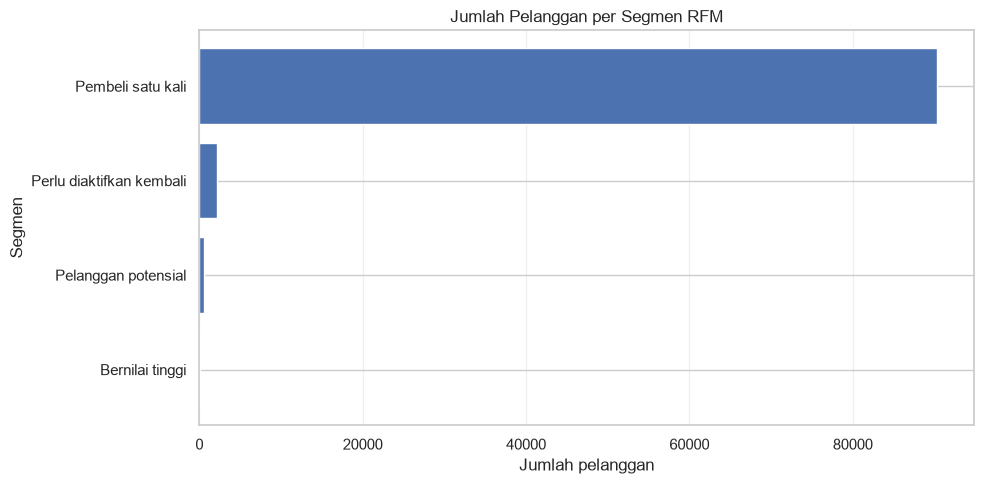

In [14]:
fig, ax = plt.subplots(figsize=(10,5))
plot_data = rfm_summary.sort_values('customers', ascending=True)
ax.barh(plot_data['segment'], plot_data['customers'])
ax.set_title('Jumlah Pelanggan per Segmen RFM')
ax.set_xlabel('Jumlah pelanggan')
ax.set_ylabel('Segmen')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Conclusion & Recommendation

### Ringkasan hasil terukur

Angka di bawah dihitung langsung dari hasil EDA yang telah dibersihkan. Gunakan ringkasan ini sebagai penghubung dari visualisasi menuju kesimpulan dan action item.

In [15]:
# Kesimpulan kuantitatif yang diturunkan langsung dari hasil analisis di atas.
peak_orders = monthly.loc[monthly['delivered_orders'].idxmax()]
peak_revenue = monthly.loc[monthly['item_revenue'].idxmax()]
top_category = category_analysis.sort_values('item_revenue', ascending=False).iloc[0]
lowest_rating_category = category_analysis[category_analysis['reviewed_orders'] >= 100].sort_values('avg_review_score').iloc[0]
delivery_lookup = delivery_summary.set_index('delivery_group')
ontime = delivery_lookup.loc['Tepat waktu / lebih cepat']
late = delivery_lookup.loc['Terlambat']
print('1) Puncak bulanan: {} mencatat {:,.0f} pesanan delivered dan R$ {:,.2f} nilai barang.'.format(peak_orders['month_label'], peak_orders['delivered_orders'], peak_revenue['item_revenue']))
print('2) Kategori dengan nilai barang tertinggi: {} (R$ {:,.2f}).'.format(top_category['category'], top_category['item_revenue']))
print('3) Kategori dengan rating terendah (minimal 100 ulasan): {} dengan skor {:.2f} dari {:,.0f} ulasan.'.format(lowest_rating_category['category'], lowest_rating_category['avg_review_score'], lowest_rating_category['reviewed_orders']))
print('4) Pesanan tepat waktu/lebih cepat memiliki rating rata-rata {:.2f}, dibanding {:.2f} pada pesanan terlambat.'.format(ontime['avg_review_score'], late['avg_review_score']))
print('5) Proporsi rating rendah adalah {:.2f}% pada pesanan tepat waktu/lebih cepat dan {:.2f}% pada pesanan terlambat.'.format(ontime['low_review_share'], late['low_review_share']))
print('6) Pelanggan dengan minimal 2 pesanan: {:.2f}% pada periode analisis.'.format(repeat_share))

1) Puncak bulanan: 2017-11 mencatat 7,289 pesanan delivered dan R$ 987,765.37 nilai barang.
2) Kategori dengan nilai barang tertinggi: health_beauty (R$ 1,229,557.50).
3) Kategori dengan rating terendah (minimal 100 ulasan): office_furniture dengan skor 3.66 dari 1,225 ulasan.
4) Pesanan tepat waktu/lebih cepat memiliki rating rata-rata 4.30, dibanding 2.27 pada pesanan terlambat.
5) Proporsi rating rendah adalah 9.14% pada pesanan tepat waktu/lebih cepat dan 62.34% pada pesanan terlambat.
6) Pelanggan dengan minimal 2 pesanan: 3.00% pada periode analisis.


### Kesimpulan

1. **Tren penjualan:** puncak bulanan pada hasil analisis muncul di **November 2017**, dengan **7.289 pesanan delivered** dan nilai barang sekitar **R$ 987,765**. Bulan tersebut bisa menjadi referensi perencanaan kapasitas, tetapi data ini tidak membuktikan penyebab kenaikannya.
2. **Kategori produk:** kategori **health_beauty** menjadi kontributor nilai barang terbesar, sekitar **R$ 1,23 juta**. Kategori **office_furniture** memiliki rating terendah, sekitar **3,65/5**, dari lebih dari 1.000 ulasan valid. Jadi, kategori besar perlu dijaga stoknya, sementara kategori rating rendah perlu ditelusuri penyebab keluhannya.
3. **Pengiriman:** rating rata-rata pesanan tepat waktu/lebih cepat sekitar **4,30**, sedangkan pesanan terlambat hanya **2,27**. Proporsi ulasan rendah (skor 1–2) pada pesanan terlambat sekitar **62%**, jauh di atas pesanan tepat waktu/lebih cepat yang sekitar **9%**. Ini menunjukkan keterlambatan sebagai prioritas investigasi, meskipun hubungan ini bukan bukti sebab-akibat.
4. **Retensi:** hanya sekitar **3%** pelanggan melakukan setidaknya dua pesanan pada periode analisis. Ini menunjukkan ruang untuk menguji program pembelian ulang, dengan evaluasi berbasis repeat purchase rate.

### Rekomendasi action item

- **Operasional logistik:** audit pesanan terlambat berdasarkan seller, wilayah, dan lama keterlambatan. Tetapkan target penurunan proporsi pesanan terlambat dan ulasan rendah, lalu pantau per bulan.
- **Kategori produk:** jaga ketersediaan kategori berkontribusi besar. Pada `office_furniture`, telusuri ulasan dan keluhan mengenai kualitas barang, deskripsi produk, kerusakan, serta ketepatan estimasi pengiriman sebelum mengambil keputusan stok.
- **Retensi pelanggan:** uji program pembelian ulang untuk pembeli satu kali serta reaktivasi untuk pelanggan lama. Nilai hasil dari repeat purchase rate dan pendapatan per pelanggan, bukan hanya jumlah pesan promosi.
- **Pemantauan:** gunakan dashboard Streamlit untuk memfilter periode dan memantau KPI yang sama secara interaktif.

**Batasan analisis:** data bersifat historis (2017–2018) dan observasional. Dataset tidak menyediakan bukti penyebab keterlambatan, biaya iklan, margin produk, atau aktivitas pelanggan setelah periode tersebut. Rekomendasi harus diuji kembali dengan data operasional terbaru sebelum diterapkan.